# Oferta habitacional de Lucas do Rio Verde (MT): entregas, investimento e demanda reprimida

**Autora:** Thamires Martins da Silva
**Fonte dos dados:** Dataset curado a partir de fontes públicas (Prefeitura de Lucas do Rio Verde, MT Par/SiHab-MT, Ministério das Cidades, Caixa Econômica Federal)
**Ferramentas:** Python (pandas, matplotlib)

---

## Contexto

Este é o segundo projeto de uma análise em duas camadas sobre habitação em Lucas do Rio Verde:

- **Camada 1** — projetou a *demanda* futura por moradia a partir do crescimento populacional (1.100 a 1.800 novas unidades/ano até 2035).
- **Camada 2 (este notebook)** — mede a *oferta* real: quantas moradias de interesse social a cidade efetivamente entregou, a quem, e como isso se compara à demanda.

> **Pergunta de negócio:** A oferta de habitação de interesse social em Lucas do Rio Verde acompanha a demanda da população que precisa dela?

## Sobre o dataset

Diferente da Camada 1 (que usou API do IBGE), este dataset foi **construído manualmente** a partir de fontes públicas — não existe base pronta de habitação municipal. Cada registro tem a URL da fonte, o que torna a análise auditável. Construir dado onde ele não vem pronto é parte central do trabalho de análise.

**Escopo:** apenas habitação de interesse social (subsídio público). Empreendimentos de alto padrão ficam de fora. O único caso de renda mais alta (Parque Primavera) recebe uma flag para poder ser separado.

## 1. Configuração do ambiente

Carga das bibliotecas e definição da paleta de cores (a mesma da Camada 1, para consistência visual entre os dois projetos).

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path

# Paleta consistente com a Camada 1
cores = {'Conservador': '#7fcdbb', 'Base': '#2c7fb8', 'Otimista': '#253494'}
COR_ENTREGUE = '#2c7fb8'
COR_OBRA = '#7fcdbb'
COR_DEMANDA = '#d95f0e'

base = Path.cwd()
print('Pasta de trabalho:', base)

Pasta de trabalho: /mnt/user-data/outputs


## 2. Carga e verificação dos dados

Dois datasets: `oferta_habitacional_lrv.csv` (empreendimentos) e `demanda_habitacional_lrv.csv` (fila de espera).

O dataset de oferta usa **colunas separadas por status** (`unidades_entregues`, `unidades_em_obra`, `unidades_previstas`), o que impede que unidades apenas planejadas sejam contadas como entregues — distinção crítica para não inflar os números.

In [2]:
oferta = pd.read_csv(base / 'oferta_habitacional_lrv.csv')
demanda = pd.read_csv(base / 'demanda_habitacional_lrv.csv')

print(f'Oferta: {len(oferta)} empreendimentos, {len(oferta.columns)} colunas')
print(f'Demanda: {len(demanda)} registro(s)')
print()
print('--- Verificação de qualidade (oferta) ---')
print(f'Valores nulos por coluna crítica:')
for c in ['unidades_entregues', 'unidades_em_obra', 'status', 'ano_entrega']:
    print(f'  {c}: {oferta[c].isna().sum()} nulos')
print()
print(f'Status possíveis: {oferta["status"].unique().tolist()}')
print(f'Total entregue: {oferta["unidades_entregues"].sum()}')
print(f'Total em obra:  {oferta["unidades_em_obra"].sum()}')

Oferta: 11 empreendimentos, 18 colunas
Demanda: 1 registro(s)

--- Verificação de qualidade (oferta) ---
Valores nulos por coluna crítica:
  unidades_entregues: 0 nulos
  unidades_em_obra: 0 nulos
  status: 0 nulos
  ano_entrega: 6 nulos

Status possíveis: ['entregue', 'em obra']
Total entregue: 1371
Total em obra:  2171


## 3. Entregas ao longo do tempo

A pergunta mais direta: quantas moradias de interesse social foram entregues por ano?

Aqui usamos **apenas** `unidades_entregues` com `status == 'entregue'` — nada que esteja em obra entra nesta contagem.

In [3]:
entregues = oferta[oferta['status'] == 'entregue'].copy()
entregues['ano_entrega'] = entregues['ano_entrega'].astype(int)

por_ano = entregues.groupby('ano_entrega')['unidades_entregues'].sum()

# Reindexar para mostrar todos os anos, inclusive os vazios
anos_completos = range(entregues['ano_entrega'].min(), entregues['ano_entrega'].max() + 1)
por_ano = por_ano.reindex(anos_completos, fill_value=0)

print('Unidades entregues por ano:')
print(por_ano.to_string())
print(f'\nTotal no período {por_ano.index.min()}-{por_ano.index.max()}: {por_ano.sum()} unidades')
print(f'Média anual: {por_ano.mean():.0f} unidades/ano')

Unidades entregues por ano:
ano_entrega
2017    350
2018      0
2019      0
2020      0
2021      0
2022    350
2023      0
2024    287
2025    192
2026    192

Total no período 2017-2026: 1371 unidades
Média anual: 137 unidades/ano


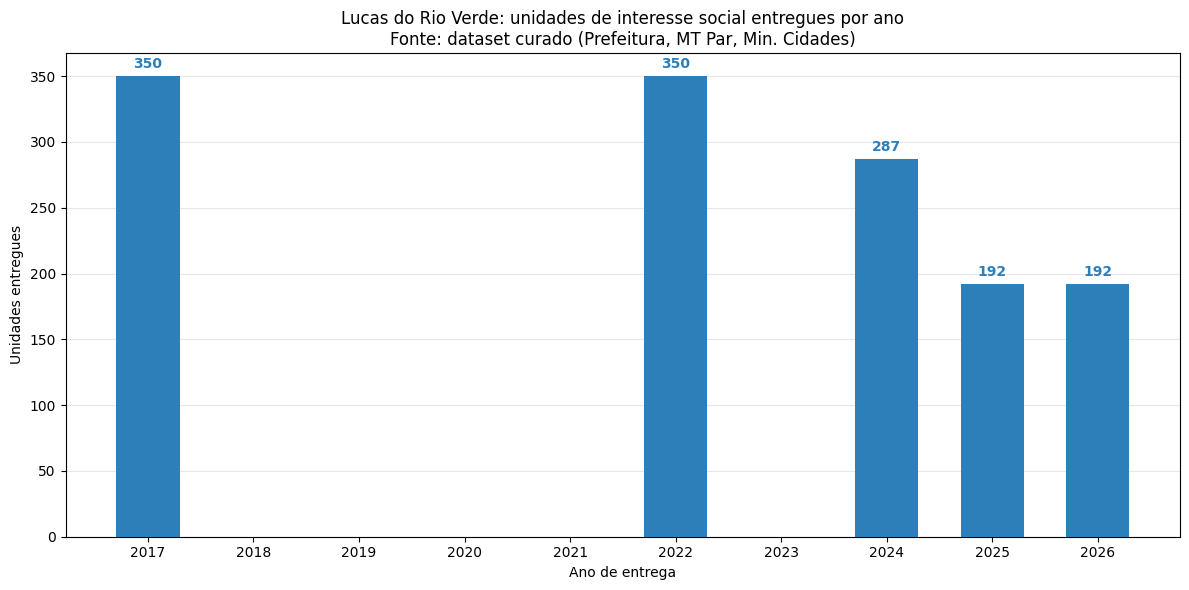

In [4]:
fig, ax = plt.subplots(figsize=(12, 6))

barras = ax.bar(por_ano.index, por_ano.values, color=COR_ENTREGUE, width=0.6, zorder=3)

# Rótulos nas barras
for x, y in zip(por_ano.index, por_ano.values):
    if y > 0:
        ax.annotate(f'{int(y)}', (x, y), textcoords='offset points',
                    xytext=(0, 6), ha='center', fontsize=10, fontweight='bold', color=COR_ENTREGUE)

ax.set_title('Lucas do Rio Verde: unidades de interesse social entregues por ano\n'
             'Fonte: dataset curado (Prefeitura, MT Par, Min. Cidades)', fontsize=12)
ax.set_xlabel('Ano de entrega')
ax.set_ylabel('Unidades entregues')
ax.set_xticks(list(por_ano.index))
ax.grid(True, axis='y', alpha=0.3, zorder=0)
plt.tight_layout()
plt.show()

### Leitura: entregas irregulares e um longo vazio

Dois padrões saltam do gráfico:

Primeiro, **a irregularidade**. As entregas não seguem um ritmo constante — vêm em ondas, atreladas à conclusão de empreendimentos específicos. Há um **vazio de cinco anos entre 2017 e 2022**, quando nenhuma unidade foi entregue. Isso reflete a natureza da política habitacional: projetos grandes, esparsos, com longos ciclos de obra, e não um fluxo contínuo de moradia.

Segundo, **a aceleração recente**. A partir de 2024, as entregas ficam anuais (2024, 2025, 2026), sinal de que a política habitacional do município se intensificou nos últimos anos — coincidindo com a criação do programa municipal Ser Luverdense (Lei 3.634/2023).

## 4. O que ainda vem: pipeline em obras

As entregas passadas contam metade da história. A outra metade é o que está sendo construído agora — o pipeline que definirá a oferta dos próximos anos.

In [5]:
em_obra = oferta[oferta['status'] == 'em obra'].copy()

total_entregue = entregues['unidades_entregues'].sum()
total_obra = em_obra['unidades_em_obra'].sum()

print(f'Já entregue (2017-2026): {total_entregue} unidades')
print(f'Em construção (pipeline): {total_obra} unidades')
print(f'Razão pipeline/entregue: {total_obra/total_entregue:.1f}x')
print()
print('--- Empreendimentos em obra ---')
for _, r in em_obra.iterrows():
    print(f'  {r["empreendimento"]}: {r["unidades_em_obra"]} un.')

Já entregue (2017-2026): 1371 unidades
Em construção (pipeline): 2171 unidades
Razão pipeline/entregue: 1.6x

--- Empreendimentos em obra ---
  Residencial Jardim Esperanca I - Modulo 1: 439 un.
  Residencial Jardim Esperanca I - Modulo 2: 303 un.
  Residencial Jardim Esperanca I - Modulo 3: 266 un.
  Residencial Jardim Esperanca I - Modulo 4: 500 un.
  Residencial Jardim Esperanca I - Modulo 5: 492 un.
  Condominio Residencial Parque Primavera: 171 un.


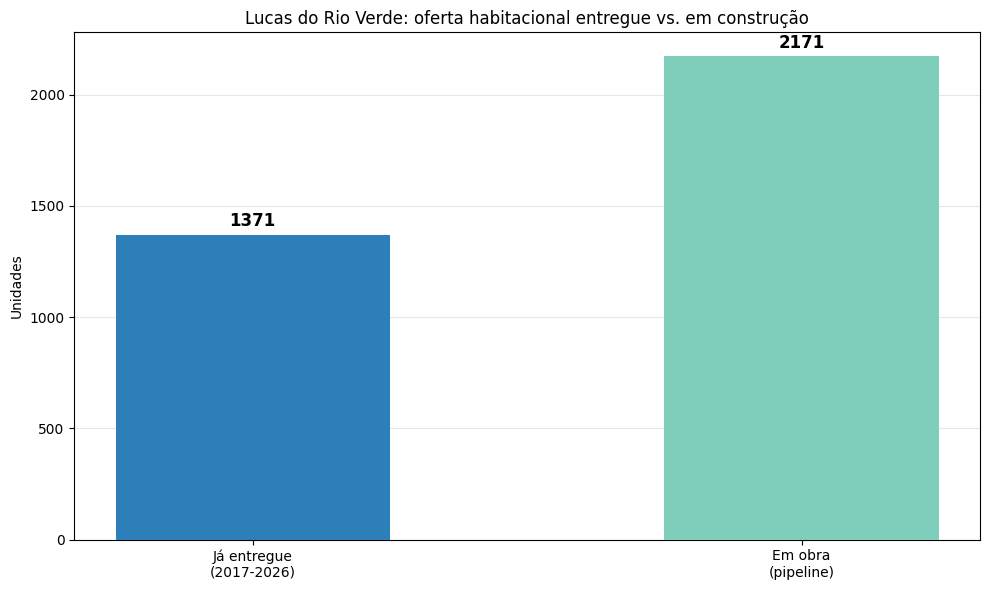

In [6]:
fig, ax = plt.subplots(figsize=(10, 6))

categorias = ['Já entregue\n(2017-2026)', 'Em obra\n(pipeline)']
valores = [total_entregue, total_obra]
cores_barras = [COR_ENTREGUE, COR_OBRA]

barras = ax.bar(categorias, valores, color=cores_barras, width=0.5, zorder=3)
for x, y in enumerate(valores):
    ax.annotate(f'{int(y)}', (x, y), textcoords='offset points',
                xytext=(0, 6), ha='center', fontsize=12, fontweight='bold')

ax.set_title('Lucas do Rio Verde: oferta habitacional entregue vs. em construção', fontsize=12)
ax.set_ylabel('Unidades')
ax.grid(True, axis='y', alpha=0.3, zorder=0)
plt.tight_layout()
plt.show()

### Leitura: a cidade está construindo mais do que já entregou

O pipeline em obras (2.171 unidades) supera tudo que foi entregue em quase uma década (1.371 unidades) — uma razão de cerca de **1,6 vez**. Isso indica uma **mudança de patamar** na política habitacional: a cidade não está apenas mantendo o ritmo histórico, está acelerando fortemente.

Se todo esse pipeline se concretizar, a oferta acumulada mais que dobra nos próximos anos. É uma aposta de política pública de porte considerável — e também o ponto onde a análise precisa de cautela: **obra em andamento não é moradia entregue**. Atrasos e paralisações são comuns no setor (o próprio Vida Nova II teve as obras paralisadas e retomadas anos depois).

## 5. Para quem e de que tipo

A política habitacional não é homogênea: atende faixas de renda diferentes, com tipos de moradia diferentes (casa, apartamento, lote urbanizado). Esta seção decompõe a oferta total (entregue + em obra) por essas dimensões.

In [7]:
oferta['unidades_total'] = oferta['unidades_previstas']

# Por tipo
por_tipo = oferta.groupby('tipo')['unidades_total'].sum().sort_values(ascending=False)
print('--- Por tipo de moradia ---')
print(por_tipo.to_string())
print()

# Por faixa de renda
por_faixa = oferta.groupby('faixa_renda')['unidades_total'].sum().sort_values(ascending=False)
print('--- Por faixa de renda ---')
print(por_faixa.to_string())

--- Por tipo de moradia ---
tipo
casa               2700
apartamento         555
lote urbanizado     287

--- Por faixa de renda ---
faixa_renda
Faixa 1-2           2000
Faixa 1              700
Faixa 2              384
nao especificada     287
R$4.400-8.000        171


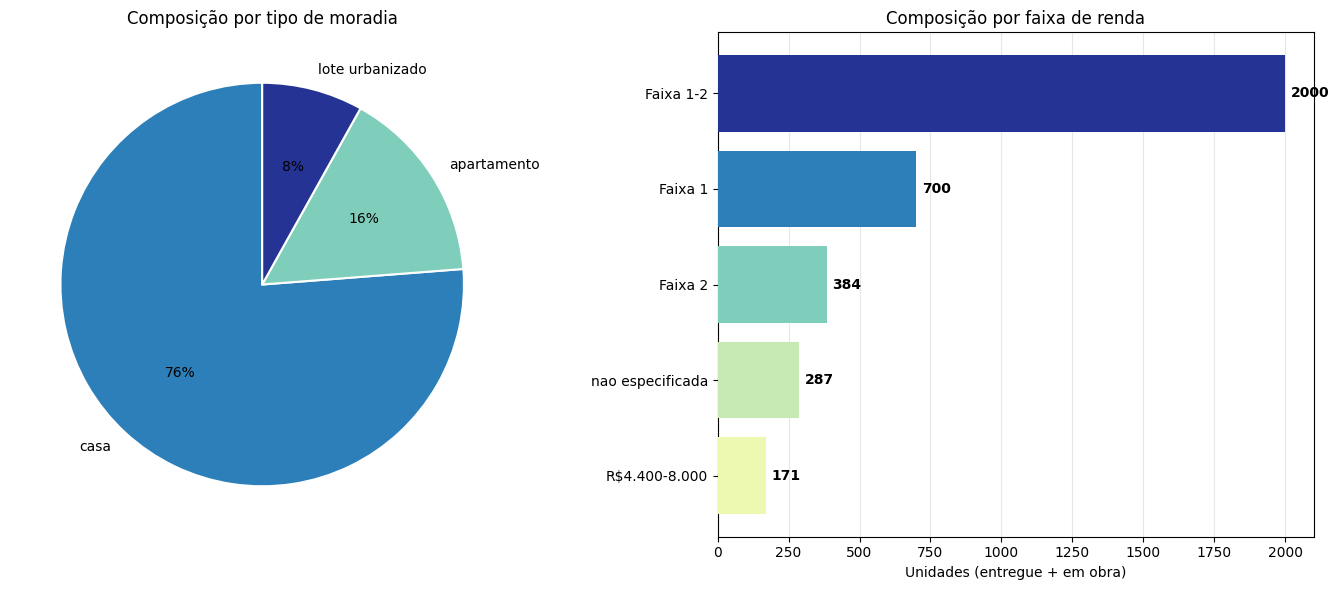

In [8]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 6))

# Gráfico de pizza por tipo
paleta_tipo = ['#2c7fb8', '#7fcdbb', '#253494', '#c7e9b4']
ax1.pie(por_tipo.values, labels=por_tipo.index, autopct='%1.0f%%',
        colors=paleta_tipo[:len(por_tipo)], startangle=90,
        wedgeprops={'edgecolor': 'white', 'linewidth': 1.5})
ax1.set_title('Composição por tipo de moradia', fontsize=12)

# Barras por faixa
paleta_faixa = ['#253494', '#2c7fb8', '#7fcdbb', '#c7e9b4', '#edf8b1']
ax2.barh(por_faixa.index[::-1], por_faixa.values[::-1],
         color=paleta_faixa[:len(por_faixa)][::-1], zorder=3)
for i, v in enumerate(por_faixa.values[::-1]):
    ax2.annotate(f'{int(v)}', (v, i), textcoords='offset points',
                 xytext=(4, 0), va='center', fontsize=10, fontweight='bold')
ax2.set_title('Composição por faixa de renda', fontsize=12)
ax2.set_xlabel('Unidades (entregue + em obra)')
ax2.grid(True, axis='x', alpha=0.3, zorder=0)

plt.tight_layout()
plt.show()

### Leitura: predomínio de casas, foco em baixa renda

O tipo dominante é **casa** — a maior parte da oferta, puxada pelo grande empreendimento Jardim Esperança (2.000 unidades). Apartamentos aparecem em segundo (Águas do Cerrado, Parque Primavera), e os lotes urbanizados do Sonho Meu representam uma modalidade distinta: entrega de terreno pronto, não moradia construída.

Quanto à faixa de renda, o grosso da oferta se concentra nas **Faixas 1 e 2** (interesse social estrito), com apenas o Parque Primavera (171 unidades, flag `False`) atendendo renda mais alta. Isso confirma que a política habitacional do município está, de fato, voltada a quem mais precisa — coerente com o objetivo declarado dos programas.

## 6. De onde vem o dinheiro

Habitação de interesse social costuma empilhar recursos de três níveis de governo. Esta seção mostra em quantos empreendimentos cada fonte aparece — revelando o grau de articulação federativa da política.

In [9]:
fontes = {
    'Federal\n(Minha Casa Minha Vida)': oferta['fonte_federal'].sum(),
    'Estadual\n(Ser Família / MT Par)': oferta['fonte_estadual'].sum(),
    'Municipal\n(Ser Luverdense)': oferta['fonte_municipal'].sum(),
}

print('Empreendimentos por fonte de recurso (de', len(oferta), 'no total):')
for k, v in fontes.items():
    print(f'  {k.replace(chr(10), " ")}: {v}')

# Quantos empilham as três fontes
tres_fontes = oferta[(oferta['fonte_federal']) & (oferta['fonte_estadual']) & (oferta['fonte_municipal'])]
print(f'\nEmpreendimentos com as TRÊS fontes empilhadas: {len(tres_fontes)} de {len(oferta)}')

Empreendimentos por fonte de recurso (de 11 no total):
  Federal (Minha Casa Minha Vida): 10
  Estadual (Ser Família / MT Par): 9
  Municipal (Ser Luverdense): 11

Empreendimentos com as TRÊS fontes empilhadas: 9 de 11


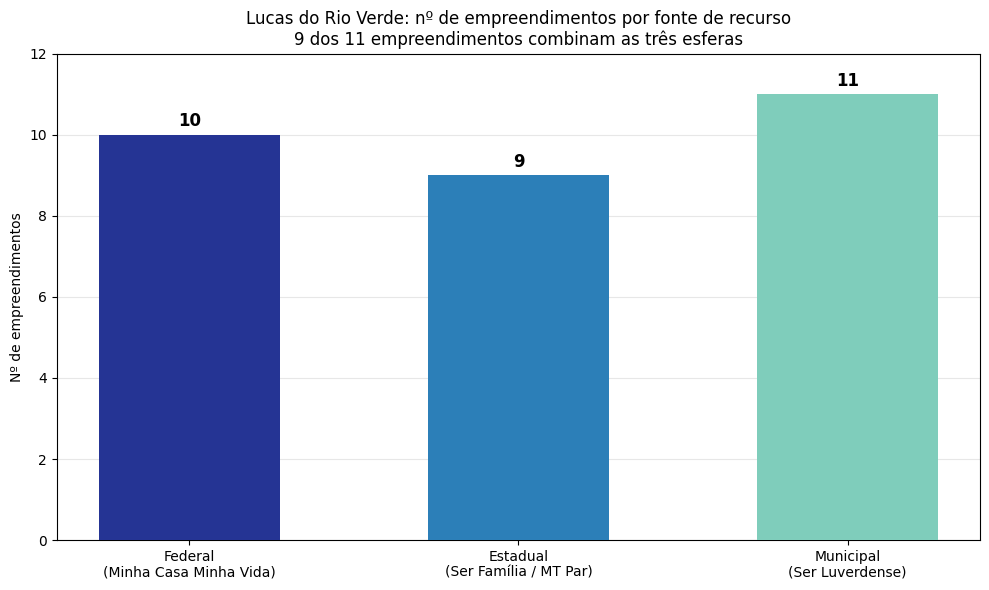

In [10]:
fig, ax = plt.subplots(figsize=(10, 6))

nomes = list(fontes.keys())
valores = list(fontes.values())
paleta_fontes = ['#253494', '#2c7fb8', '#7fcdbb']

barras = ax.bar(nomes, valores, color=paleta_fontes, width=0.55, zorder=3)
for x, y in enumerate(valores):
    ax.annotate(f'{int(y)}', (x, y), textcoords='offset points',
                xytext=(0, 6), ha='center', fontsize=12, fontweight='bold')

ax.set_title('Lucas do Rio Verde: nº de empreendimentos por fonte de recurso\n'
             f'{len(tres_fontes)} dos {len(oferta)} empreendimentos combinam as três esferas', fontsize=12)
ax.set_ylabel('Nº de empreendimentos')
ax.set_ylim(0, len(oferta) + 1)
ax.grid(True, axis='y', alpha=0.3, zorder=0)
plt.tight_layout()
plt.show()

### Leitura: uma política de articulação federativa

A fonte **federal** (Minha Casa Minha Vida) está presente em quase todos os empreendimentos — é a espinha dorsal do financiamento. Mas o dado mais revelador é quantos projetos **empilham as três esferas** (federal + estadual + municipal): a maioria. Isso mostra que a viabilização da moradia em Lucas do Rio Verde depende de uma articulação entre os três níveis de governo — o município entra tipicamente com o terreno, o estado com subsídio (Ser Família/MT Par) e a União com o financiamento principal.

Essa dependência tripla é uma força (mais recursos) e uma fragilidade (mais pontos de falha): se qualquer esfera trava, o projeto emperra.

## 7. Oferta vs. demanda: a conta que não fecha

Esta é a análise central do projeto — o cruzamento das duas camadas.

De um lado, a **demanda reprimida**: em 2021, o Sistema de Gestão Habitacional do município tinha ~5.800 famílias inscritas, ~4.000 delas no perfil Faixa 1.

De outro, a **oferta entregue**: 1.371 unidades em toda a série histórica.

In [11]:
fila_2021 = int(demanda.iloc[0]['inscritos_total'])
fila_faixa1 = int(demanda.iloc[0]['inscritos_faixa1'])

cobertura = total_entregue / fila_2021 * 100
deficit = fila_2021 - total_entregue

print('=== OFERTA x DEMANDA ===')
print(f'Fila de espera (2021, total):     {fila_2021:>6} famílias')
print(f'Fila de espera (2021, Faixa 1):   {fila_faixa1:>6} famílias')
print(f'Entregue em toda a série:         {total_entregue:>6} unidades')
print(f'Em obra (pipeline futuro):        {total_obra:>6} unidades')
print()
print(f'Cobertura da fila por entregas:   {cobertura:.1f}%')
print(f'Déficit residual (fila - entregue): {deficit} famílias')
print()
print('Mesmo somando o pipeline em obra à oferta entregue:')
oferta_total = total_entregue + total_obra
print(f'  Oferta total (entregue + obra):  {oferta_total} unidades')
print(f'  vs. fila de 2021:                {fila_2021} famílias')
print(f'  Cobertura potencial:             {oferta_total/fila_2021*100:.1f}%')

=== OFERTA x DEMANDA ===
Fila de espera (2021, total):       5800 famílias
Fila de espera (2021, Faixa 1):     4000 famílias
Entregue em toda a série:           1371 unidades
Em obra (pipeline futuro):          2171 unidades

Cobertura da fila por entregas:   23.6%
Déficit residual (fila - entregue): 4429 famílias

Mesmo somando o pipeline em obra à oferta entregue:
  Oferta total (entregue + obra):  3542 unidades
  vs. fila de 2021:                5800 famílias
  Cobertura potencial:             61.1%


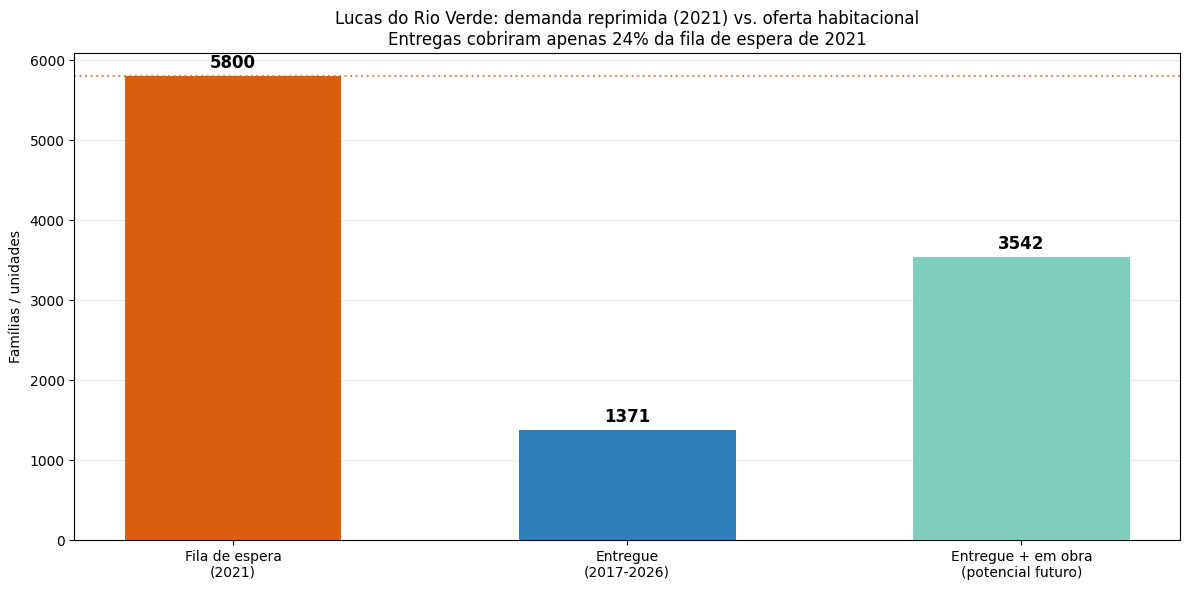

In [12]:
fig, ax = plt.subplots(figsize=(12, 6))

categorias = ['Fila de espera\n(2021)', 'Entregue\n(2017-2026)', 'Entregue + em obra\n(potencial futuro)']
valores = [fila_2021, total_entregue, oferta_total]
cores_barras = [COR_DEMANDA, COR_ENTREGUE, COR_OBRA]

barras = ax.bar(categorias, valores, color=cores_barras, width=0.55, zorder=3)
for x, y in enumerate(valores):
    ax.annotate(f'{int(y)}', (x, y), textcoords='offset points',
                xytext=(0, 6), ha='center', fontsize=12, fontweight='bold')

# Linha da fila para comparação visual
ax.axhline(fila_2021, color=COR_DEMANDA, linestyle=':', linewidth=1.5, alpha=0.7, zorder=2)

ax.set_title('Lucas do Rio Verde: demanda reprimida (2021) vs. oferta habitacional\n'
             f'Entregas cobriram apenas {cobertura:.0f}% da fila de espera de 2021', fontsize=12)
ax.set_ylabel('Famílias / unidades')
ax.grid(True, axis='y', alpha=0.3, zorder=0)
plt.tight_layout()
plt.show()

### Leitura: a política atende uma fração da necessidade

O número é contundente: as entregas de quase uma década cobriram apenas **~24% da fila de espera de 2021**. Restam mais de 4.400 famílias que estavam cadastradas e não foram atendidas por moradia entregue.

Há duas ressalvas honestas que **atenuam** o quadro: (1) o pipeline em obra, se concluído, elevaria a cobertura potencial para ~61% da fila de 2021; (2) parte da fila pode ter sido atendida por vias não capturadas aqui (financiamento direto, mercado).

E há uma ressalva que **agrava**: a fila de 5.800 é de 2021. Com o crescimento populacional acelerado que a Camada 1 documentou, é quase certo que a demanda cresceu desde então — o denominador real hoje é maior, e a cobertura, menor.

## 8. Conexão com a Camada 1: oferta vs. demanda projetada

A fila de espera mede a demanda *acumulada* (estoque). A Camada 1 projetou a demanda *anual* (fluxo): quantas moradias novas o crescimento populacional exige a cada ano.

Colocar as duas lado a lado revela se a cidade constrói no ritmo que a própria demografia impõe.

In [13]:
# Demanda anual projetada na Camada 1 (cenários)
demanda_anual = {'Conservador': 1098, 'Base': 1484, 'Otimista': 1794}

# Oferta anual média (entregue)
oferta_media_anual = por_ano[por_ano > 0].mean()  # média dos anos com entrega
oferta_media_periodo = por_ano.sum() / len(por_ano)  # média incluindo anos vazios

print('=== DEMANDA ANUAL PROJETADA (Camada 1) ===')
for k, v in demanda_anual.items():
    print(f'  Cenário {k}: {v} novas moradias/ano')
print()
print('=== OFERTA ANUAL REAL (Camada 2) ===')
print(f'  Média nos anos com entrega:      {oferta_media_anual:.0f} unidades/ano')
print(f'  Média no período (2017-2026):    {oferta_media_periodo:.0f} unidades/ano')
print()
print('=== O DESCOMPASSO ===')
print(f'  Demanda anual (cenário Base):    {demanda_anual["Base"]} moradias/ano')
print(f'  Oferta anual média (período):    {oferta_media_periodo:.0f} moradias/ano')
print(f'  Déficit de fluxo anual:          {demanda_anual["Base"] - oferta_media_periodo:.0f} moradias/ano não atendidas')

=== DEMANDA ANUAL PROJETADA (Camada 1) ===
  Cenário Conservador: 1098 novas moradias/ano
  Cenário Base: 1484 novas moradias/ano
  Cenário Otimista: 1794 novas moradias/ano

=== OFERTA ANUAL REAL (Camada 2) ===
  Média nos anos com entrega:      274 unidades/ano
  Média no período (2017-2026):    137 unidades/ano

=== O DESCOMPASSO ===
  Demanda anual (cenário Base):    1484 moradias/ano
  Oferta anual média (período):    137 moradias/ano
  Déficit de fluxo anual:          1347 moradias/ano não atendidas


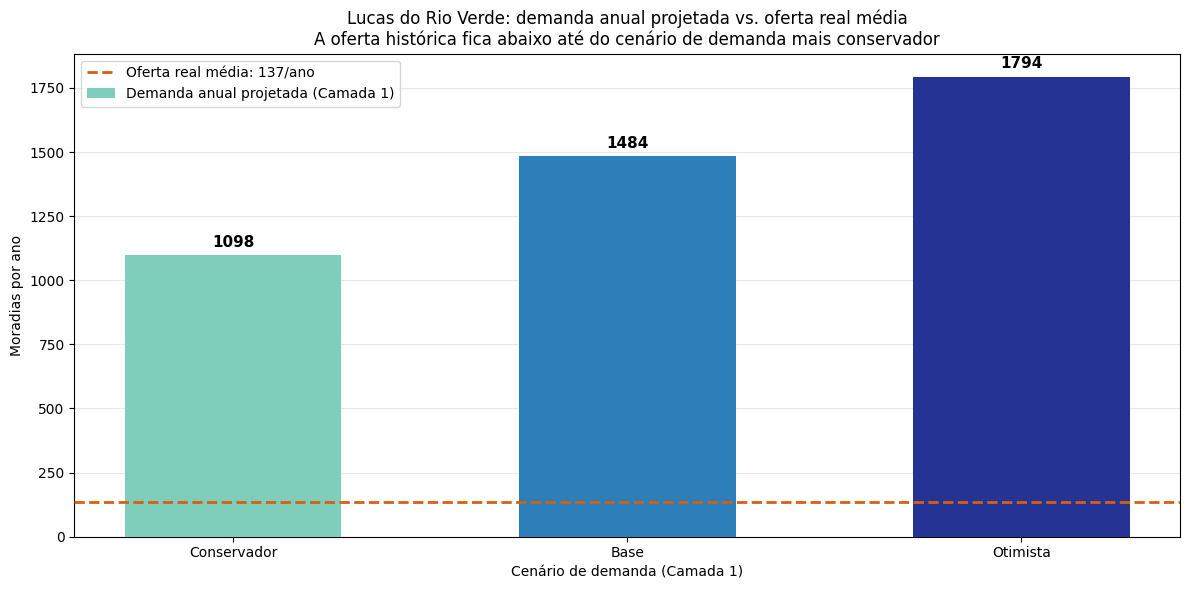

In [14]:
fig, ax = plt.subplots(figsize=(12, 6))

# Barras de demanda projetada (3 cenários)
x_dem = [0, 1, 2]
vals_dem = [demanda_anual['Conservador'], demanda_anual['Base'], demanda_anual['Otimista']]
ax.bar(x_dem, vals_dem, color=[cores['Conservador'], cores['Base'], cores['Otimista']],
       width=0.55, zorder=3, label='Demanda anual projetada (Camada 1)')
for x, y in zip(x_dem, vals_dem):
    ax.annotate(f'{int(y)}', (x, y), textcoords='offset points',
                xytext=(0, 6), ha='center', fontsize=11, fontweight='bold')

# Linha da oferta real média
ax.axhline(oferta_media_periodo, color=COR_DEMANDA, linestyle='--', linewidth=2, zorder=4,
           label=f'Oferta real média: {oferta_media_periodo:.0f}/ano')

ax.set_xticks(x_dem)
ax.set_xticklabels(['Conservador', 'Base', 'Otimista'])
ax.set_title('Lucas do Rio Verde: demanda anual projetada vs. oferta real média\n'
             'A oferta histórica fica abaixo até do cenário de demanda mais conservador', fontsize=12)
ax.set_ylabel('Moradias por ano')
ax.set_xlabel('Cenário de demanda (Camada 1)')
ax.legend(loc='upper left')
ax.grid(True, axis='y', alpha=0.3, zorder=0)
plt.tight_layout()
plt.show()

### Leitura: a oferta histórica não acompanha nem o cenário mais tímido

Este é o achado que amarra os dois projetos. A demanda anual projetada pela Camada 1 — mesmo no cenário **Conservador** (1.098 moradias/ano) — supera a oferta real média histórica (~137/ano no período completo, ~274/ano se contarmos só anos com entrega).

Em outras palavras: **só o crescimento populacional gera, a cada ano, mais demanda do que a cidade historicamente entregou.** E isso sem contar o estoque reprimido da fila. A conta estrutural não fecha pela oferta histórica.

O pipeline em obra muda esse quadro se concretizado: 2.171 unidades nos próximos ~2-3 anos representariam algo como 700-1.000 unidades/ano, aproximando-se do cenário Conservador de demanda. Ou seja, **a aceleração recente é exatamente a resposta que a demografia exige — mas ela precisa se manter, não ser um pico isolado.**

## 9. Limitações

1. **Dataset curado manualmente.** Construído a partir de notícias e portais oficiais, não de uma base estruturada. É auditável (toda linha tem fonte), mas pode conter empreendimentos não capturados.
2. **Fila de espera é um ponto único (2021).** Não há série histórica pública da demanda cadastrada. A evolução ano a ano exigiria pedido via LAI à MT Par/SiHab-MT.
3. **Investimento incompleto.** Só o Vida Nova II tem valor consolidado (R$ 27,9 mi, Min. Cidades). Os demais exigiriam consulta a licitações no portal de transparência ou LAI.
4. **Programa de 2013 não confirmado.** Uma iniciativa de ~2.465 casas foi anunciada em 2013 (construtora Aurora), mas as entregas efetivas não puderam ser confirmadas em fonte pública — pode haver oferta anterior a 2017 não capturada.
5. **Obra ≠ entrega.** O pipeline de 2.171 unidades é uma promessa, não um fato. Atrasos são comuns (o Vida Nova II foi paralisado e retomado).
6. **Demanda anual da Camada 1 é projeção.** Herda as incertezas daquele modelo (taxa de crescimento constante, etc.).

## 10. Síntese executiva

Lucas do Rio Verde entregou **1.371 unidades de habitação de interesse social** entre 2017 e 2026, de forma irregular e com um vazio de cinco anos (2017–2022). A política se intensificou a partir de 2024 e tem hoje um **pipeline de 2.171 unidades em obra** — mais do que tudo já entregue, sinalizando uma mudança de patamar.

Ainda assim, **a oferta não acompanha a demanda**. As entregas cobriram apenas ~24% da fila de espera de 2021 (5.800 famílias), e a demanda *anual* projetada pela Camada 1 — mesmo no cenário mais conservador (1.098 moradias/ano) — supera a média histórica de oferta. A conta estrutural só começa a fechar se o pipeline atual se concretizar **e** o ritmo acelerado se mantiver nos próximos anos.

A política habitacional do município é de forte articulação federativa (a maioria dos projetos empilha recursos federais, estaduais e municipais) e voltada majoritariamente às Faixas 1 e 2 de renda — coerente com seu objetivo social. O desafio não é de foco, é de **escala e continuidade**: a demografia de uma das cidades que mais cresce no Brasil impõe um ritmo que a oferta histórica não alcançou.

Para o setor de construção e para a gestão pública, a leitura é direta: a demanda por moradia popular é estrutural e crescente, e há espaço para muito mais oferta do que a cidade historicamente produziu.